# Phase 3 – Problemfelder erkennen (F2)

Darstellung der vorhandenen Ergebnisse aus `results/2026-10-16_round3/phase3.json` und `phase3_cases.csv`. Es wird nichts neu trainiert, keine österreichischen Daten.

**Wichtiger Hinweis:** Der Kandidat (**M-alle-rel Ridge S2**, S2-Basis, 89 Feld-Jahre / 8 Standort-Jahre) hat das Kriterium „stark genug“ in **Phase 4 nicht bestanden** (keine Stufe, auch nicht Runde 3). Es gibt daher **keine Freeze-Freigabe** und keinen Österreich-Test. Alle Zahlen unten sind Ergebnisse eines Kandidaten ohne Freigabe, mit breiten KI.
Problemfeld = gefährdet: RY < 0,85 (Prävalenz 0,33). Validierung LOFYO, 95-%-KI per Cluster-Bootstrap über Standort-Jahre.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Resolve repo root whether run from notebooks/ or the root
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
R3 = ROOT / "results" / "2026-10-16_round3"
FIG = ROOT / "reports" / "figures"

pd.options.display.float_format = "{:.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

p3 = json.loads((R3 / "phase3.json").read_text(encoding="utf-8"))
crit3 = json.loads((R3 / "criteria.json").read_text(encoding="utf-8"))
print("Kandidat:", p3["model"]["model"], p3["model"]["kind"], p3["model"]["basis"])
print("Phase 4 bestanden (strong_enough):", crit3["strong_enough"])

CUTS = list(p3["per_cutoff"])
CUT_LABEL = {c: f"{int(c[3:])}.{int(c[:2])}." for c in CUTS}

Kandidat: M-alle-rel ridge S2
Phase 4 bestanden (strong_enough): False


## 1. PR-AUC je Stichtag

(a) Schwelle auf dem vorhergesagten RY, (b) direkter Klassifikator „gefährdet ja/nein“, Referenz = Stress-Score (Abstand der eigenen S2-NDVI-Kurve zur Referenzkurve „gesunder Mais“, nur aus Trainingsfolds, ohne gelernte Parameter).
Ein Zufallsmodell hat PR-AUC ≈ Prävalenz. Der Stress-Score braucht Sommertermine: Zeilen mit weniger Feld-Jahren (n) und anderer Prävalenz, am 1.6. nicht verfügbar.

In [2]:
rows = []
for c in CUTS:
    pc = p3["per_cutoff"][c]
    a, b, r = pc["a_threshold_on_pred_RY"], pc["b_direct_classifier"], pc["reference_stress_score"]
    ci = lambda d: f"{d['pr_auc']:.2f} [{d['pr_auc_lo']:.2f}; {d['pr_auc_hi']:.2f}]" if d["n"] else "–"
    rows.append({"Stichtag": CUT_LABEL[c], "n": a["n"], "Prävalenz": a["prevalence"],
                 "(a) PR-AUC [KI]": ci(a), "(a) Recall@20 % FPR": a["recall_at_20fpr"],
                 "(b) PR-AUC [KI]": ci(b), "(b) Recall@20 % FPR": b["recall_at_20fpr"],
                 "Ref. n": r["n"], "Ref. Prävalenz": r["prevalence"] if r["n"] else np.nan,
                 "Ref. ρ mit RY": r["spearman_RY"] if r["n"] else np.nan,
                 "Ref. PR-AUC [KI]": ci(r), "Ref. Recall@20 % FPR": r["recall_at_20fpr"] if r["n"] else np.nan})
tab = pd.DataFrame(rows)
display(tab.set_index("Stichtag"))

,n,Prävalenz,(a) PR-AUC [KI],(a) Recall@20 % FPR,(b) PR-AUC [KI],(b) Recall@20 % FPR,Ref. n,Ref. Prävalenz,Ref. ρ mit RY,Ref. PR-AUC [KI],Ref. Recall@20 % FPR
Stichtag,,,,,,,,,,,
1.6.,89,0.33,0.35 [0.25; 0.67],0.24,0.38 [0.27; 0.73],0.31,0,NaN,NaN,–,NaN
15.6.,89,0.33,0.31 [0.23; 0.56],0.03,0.36 [0.29; 0.73],0.31,52,0.27,0.23,0.58 [0.14; 0.88],0.43
1.7.,89,0.33,0.35 [0.21; 0.58],0.21,0.29 [0.23; 0.48],0.10,89,0.33,0.19,0.60 [0.42; 0.80],0.55
15.7.,89,0.33,0.32 [0.23; 0.51],0.21,0.35 [0.24; 0.63],0.31,89,0.33,0.28,0.54 [0.30; 0.81],0.45
1.8.,89,0.33,0.44 [0.33; 0.80],0.52,0.32 [0.24; 0.59],0.28,89,0.33,0.21,0.62 [0.37; 0.88],0.41
15.8.,89,0.33,0.40 [0.27; 0.80],0.38,0.37 [0.22; 0.75],0.28,89,0.33,0.29,0.64 [0.40; 0.86],0.41
1.9.,89,0.33,0.40 [0.32; 0.82],0.21,0.38 [0.28; 0.67],0.28,89,0.33,0.43,0.71 [0.43; 0.90],0.69


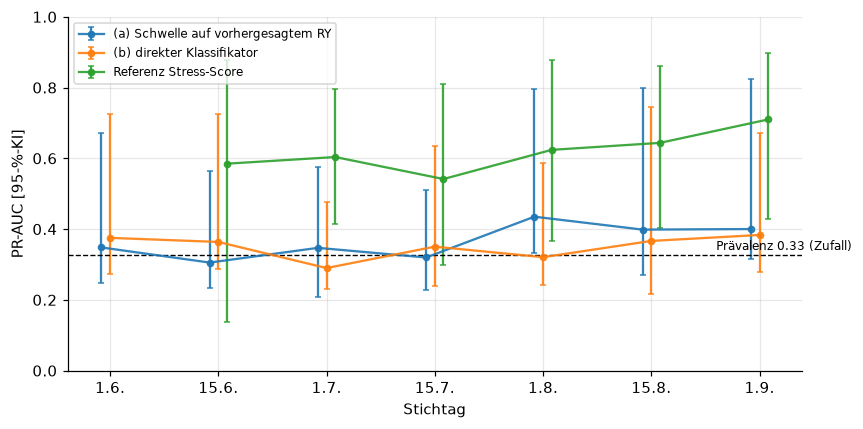

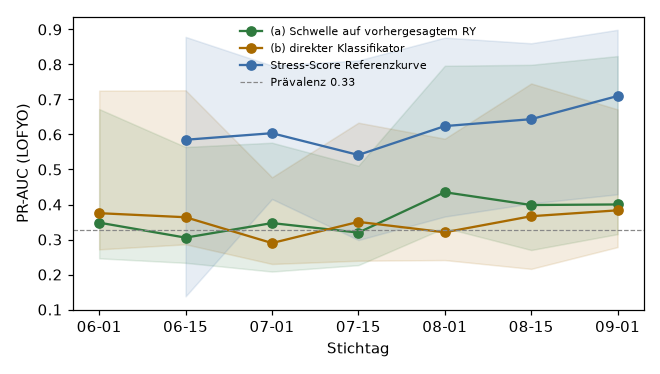

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CUTS))
series = [("a_threshold_on_pred_RY", "(a) Schwelle auf vorhergesagtem RY", "#1f77b4", -0.08),
          ("b_direct_classifier", "(b) direkter Klassifikator", "#ff7f0e", 0.0),
          ("reference_stress_score", "Referenz Stress-Score", "#2ca02c", 0.08)]
for key, lab, col, off in series:
    d = [p3["per_cutoff"][c][key] for c in CUTS]
    ok = np.array([bool(v["n"]) for v in d])
    pr = np.array([v["pr_auc"] if v["n"] else np.nan for v in d])
    lo = np.array([v["pr_auc_lo"] if v["n"] else np.nan for v in d])
    hi = np.array([v["pr_auc_hi"] if v["n"] else np.nan for v in d])
    ax.errorbar(x[ok] + off, pr[ok], yerr=[(pr - lo)[ok], (hi - pr)[ok]], fmt="-o", ms=4, capsize=2,
                color=col, label=lab, alpha=0.9)
prev = p3["per_cutoff"][CUTS[0]]["a_threshold_on_pred_RY"]["prevalence"]
ax.axhline(prev, color="k", ls="--", lw=0.9)
ax.text(len(CUTS) - 1.4, prev + 0.015, f"Prävalenz {prev:.2f} (Zufall)", fontsize=8)
ax.set_xticks(x, [CUT_LABEL[c] for c in CUTS])
ax.set_xlabel("Stichtag")
ax.set_ylabel("PR-AUC [95-%-KI]")
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
display(Image(FIG / "phase3_earlywarning_risk.png", width=600))

**Lesart:** Die gelernten Modelle (a, b) liegen bis Mitte Juli auf Zufallsniveau und ab August nur knapp darüber; die KI berühren die Prävalenz.
Das einfachste Werkzeug, der Stress-Score aus der Referenzkurve, ist am besten (PR-AUC 0,71 am 1.9., ρ mit RY 0,43), hat aber nur n = 52–89 Feld-Jahre und ebenfalls breite KI.

## 2. Ursachen der gefährdeten Feld-Jahre

30 gefährdete Feld-Jahre in der HLS-Zeit. Die Ursachen-Regeln wurden vor der Auswertung festgelegt (DECISIONS 2026-10-16). Es sind Plausibilitäts-Zuordnungen (Wetter aus ERA5-Land, ca. 9 km), **keine Kausalbeweise**; Krankheiten und Schädlinge werden nicht behauptet.
Ein Feld-Jahr kann mehrere Ursachen haben: Die Zählung je Ursache (links) zählt es unter jeder Ursache, die Aufteilung je Standort-Jahr (rechts) nach Ursachen-Kombination.

,Anzahl (je Ursache)
Ursache unklar,16
Nässe,9
Hitze,5
Trockenstress,3
abrupter Schaden,2


,Hitze,Nässe,Ursache unklar,"Trockenstress, Nässe","Nässe, abrupter Schaden",Summe Feld-Jahre
Standort-Jahr,,,,,,
BARC-2017,4,0,0,0,0,4
BARC-2018,0,2,0,0,0,2
BARC-2019,1,0,0,0,0,1
KBS-2014,0,0,1,0,0,1
KBS-2017,0,0,9,0,0,9
KBS-2020,0,2,0,3,2,7
KBS-2023,0,0,6,0,0,6


Summe gefährdeter Feld-Jahre: 30


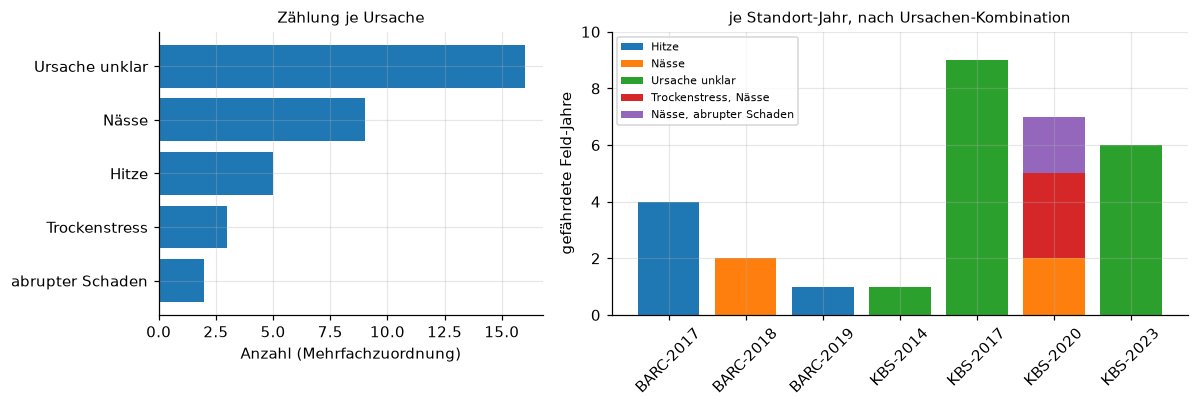

In [4]:
cc = pd.Series(p3["causes_counts"]).sort_values(ascending=False)
sy = pd.DataFrame(p3["causes_by_site_year"]).T.fillna(0).astype(int)
sy.index.name = "Standort-Jahr"
sy["Summe Feld-Jahre"] = sy.sum(axis=1)
display(cc.rename("Anzahl (je Ursache)").to_frame())
display(sy)
print("Summe gefährdeter Feld-Jahre:", int(sy["Summe Feld-Jahre"].sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(cc.index, cc.values, color="#1f77b4")
axes[0].invert_yaxis()
axes[0].set_xlabel("Anzahl (Mehrfachzuordnung)")
axes[0].set_title("Zählung je Ursache", fontsize=10)
combos = sy.drop(columns="Summe Feld-Jahre")
bottom = np.zeros(len(combos))
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
for col, color in zip(combos.columns, palette):
    axes[1].bar(combos.index, combos[col], bottom=bottom, label=col, color=color)
    bottom += combos[col].values
axes[1].set_ylabel("gefährdete Feld-Jahre")
axes[1].set_ylim(0, 10)
axes[1].set_title("je Standort-Jahr, nach Ursachen-Kombination", fontsize=10)
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Einschränkung:** Bei KBS sind 13 von 23 gefährdeten Feld-Jahren Bio-Parzellen (T4); „gefährdet“ misst dort zu einem großen Teil, in welchem Jahr die Bio-Bewirtschaftung schwächelt (Unkraut, Stickstoff), nicht Wetterstress. Das erklärt die vielen „Ursache unklar“ (16 von 35 Zuordnungen) und ist eine Grenze für die Übertragung auf konventionelle Praxisfelder (`reports/data_review/phase3_problem_fields.md`).

## 3. Fallstudien (Regel a, Stichtag 1.9.)

Je drei richtig erkannte, verpasste und fehlalarmierte Feld-Jahre. RY = relativer Ertrag (Spalten: gemessen und vorhergesagt); Schwelle für „gefährdet“ 0,85.

In [5]:
cases = pd.read_csv(R3 / "phase3_cases.csv")
cases["causes"] = cases["causes"].fillna("– (nicht gefährdet)")
cases["fy_key"] = cases["fy_key"].str.split("|").str[1]
order = {"richtig erkannt": 0, "verpasst": 1, "Fehlalarm": 2}
cases = cases.sort_values("case", key=lambda s: s.map(order), kind="stable")
display(cases.rename(columns={"case": "Fall", "fy_key": "Parzelle", "dataset": "Datensatz", "year": "Jahr",
                              "y": "RY gemessen", "pred": "RY vorhergesagt", "causes": "Ursache"})
        .reset_index(drop=True))

,Fall,Parzelle,Datensatz,Jahr,RY gemessen,RY vorhergesagt,Ursache
0,richtig erkannt,KBS:T4R6,KBS,2017,0.30,0.75,Ursache unklar
1,richtig erkannt,KBS:T4R4,KBS,2017,0.44,0.56,Ursache unklar
2,richtig erkannt,KBS:T4R5,KBS,2017,0.45,0.64,Ursache unklar
3,verpasst,KBS:T4R1,KBS,2017,0.41,0.88,Ursache unklar
4,verpasst,KBS:T4R4,KBS,2023,0.50,1.01,Ursache unklar
5,verpasst,KBS:T4R2,KBS,2023,0.51,1.00,Ursache unklar
6,Fehlalarm,KBS:T4R1,KBS,2020,1.00,0.56,– (nicht gefährdet)
7,Fehlalarm,KBS:T1R4,KBS,2017,0.97,0.58,– (nicht gefährdet)
8,Fehlalarm,KBS:T2R1,KBS,2017,0.94,0.60,– (nicht gefährdet)


Auffällig: Alle sechs gefährdeten Fälle liegen bei KBS und sind ohne klare Wetterursache (Ursache unklar); die Fehlalarme sind KBS-Parzellen mit hohem gemessenem RY (0,94–1,00), für die das Modell einen niedrigen Wert vorhersagt.
Die Fälle zeigen, dass das Modell keine Ursachen erkennt, sondern Standort- und Jahresmuster.

## 4. Gewählter Stressindikator (PLAN 3.5)

Indikator: **EVI, K4 (Integral der Kurve)**, Spearman ρ mit RY je Datensatz. Voraussetzung ρ ≥ 0,4 ist erfüllt, der Indikator ist damit festgelegt. KBS-KI aus nur 2 unabhängigen Standort-Jahren (praktisch keine Aussagekraft), BARC-KI schließt 0 ein.

Indikator: EVI K4 integral | Median-ρ über KBS/BARC: 0.49 | Voraussetzung ρ ≥ 0,4 erfüllt: True | festgelegt: True


,Datensatz,n Feld-Jahre,Cluster (Standort-Jahre),ρ,KI unten,KI oben
0,KBS,48,2,0.47,0.44,0.47
1,BARC,26,7,0.50,-0.04,0.87
2,pooled,74,9,0.44,0.10,0.75


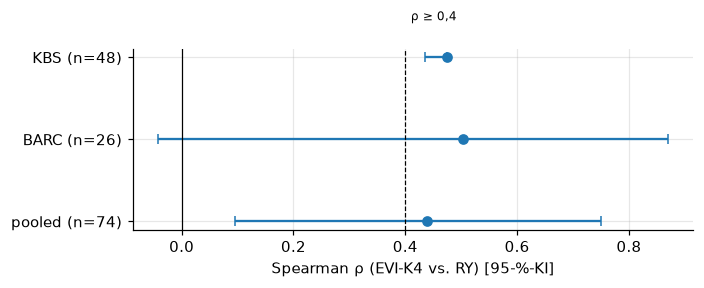

In [6]:
ic = p3["indicator_choice"]
print(f"Indikator: {ic['index'].upper()} {ic['indicator']} | Median-ρ über KBS/BARC: {ic['median_rho']:.2f} | "
      f"Voraussetzung ρ ≥ 0,4 erfüllt: {ic['precondition_rho_ge_0.4']} | festgelegt: {ic['chosen']}")
ind = pd.DataFrame(ic["per_dataset"])
display(ind.rename(columns={"dataset": "Datensatz", "n": "n Feld-Jahre", "clusters": "Cluster (Standort-Jahre)",
                            "rho": "ρ", "lo": "KI unten", "hi": "KI oben"}))

fig, ax = plt.subplots(figsize=(6.5, 2.8))
y = np.arange(len(ind))
ax.errorbar(ind["rho"], y, xerr=[ind["rho"] - ind["lo"], ind["hi"] - ind["rho"]], fmt="o", capsize=3, color="#1f77b4")
ax.axvline(0, color="k", lw=0.8)
ax.axvline(0.4, color="k", ls="--", lw=0.8)
ax.text(0.41, -0.45, "ρ ≥ 0,4", fontsize=8)
ax.set_yticks(y, ind["dataset"] + " (n=" + ind["n"].astype(str) + ")")
ax.invert_yaxis()
ax.set_xlabel("Spearman ρ (EVI-K4 vs. RY) [95-%-KI]")
plt.tight_layout()
plt.show()

**Hinweis (Status):** Das Kriterium „stark genug“ (Phase 4) ist für den Kandidaten in **allen** Stufen nicht erfüllt (`reports/phase4_stark_genug.md`): RMSE nicht besser als „normales Jahr“ und ρ am 1.9. unter 0,4. Die hier gezeigten Problemfeld-Ergebnisse sind daher Exploration, kein freigegebenes Modell; nach PLAN Phase 4 geht nichts nach Österreich, solange der Projektinhaber nichts anderes entscheidet.